# Démo plutovizu

Tour d'horizon de l'API chaînable : chaque méthode retourne le graphique, on enchaîne les appels et on termine par `.show()`.

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from plutovizu import (Chart, get_fonts, list_themes, set_theme, texture_class,
                       theme_context)

## Données d'exemple

In [2]:
rng = np.random.default_rng(42)
n = 120
jours = np.arange(n)
effet_categorie = {'A': 150, 'B': -80, 'C': 40, 'D': -150}

ventes = pd.DataFrame({
    'date': pd.date_range('2024-01-01', periods=n, freq='D'),
    'categorie': rng.choice(list(effet_categorie), n),
    'temperature': rng.normal(27, 4, n).round(1),
})
# tendance + cycle mensuel + effet de la catégorie + bruit
ventes['ventes'] = (np.linspace(900, 1300, n) + 120 * np.sin(jours * 2 * np.pi / 30)
                    + ventes['categorie'].map(effet_categorie) + rng.normal(0, 40, n))
ventes['profit'] = ventes['ventes'] * 0.18 + rng.normal(0, 15, n)
ventes['visiteurs'] = (20 + 2.2 * ventes['temperature'] + rng.normal(0, 6, n)).round().astype(int)
ventes.head()

,date,categorie,temperature,ventes,profit,visiteurs
0,2024-01-01,A,23.5,1045.254467,161.794977,71
1,2024-01-02,D,30.9,789.743793,147.073815,96
2,2024-01-03,C,20.3,1047.771156,214.509061,65
3,2024-01-04,B,25.7,909.393564,140.682920,72
4,2024-01-05,B,27.7,906.185668,176.070840,77


## 1. Courbes

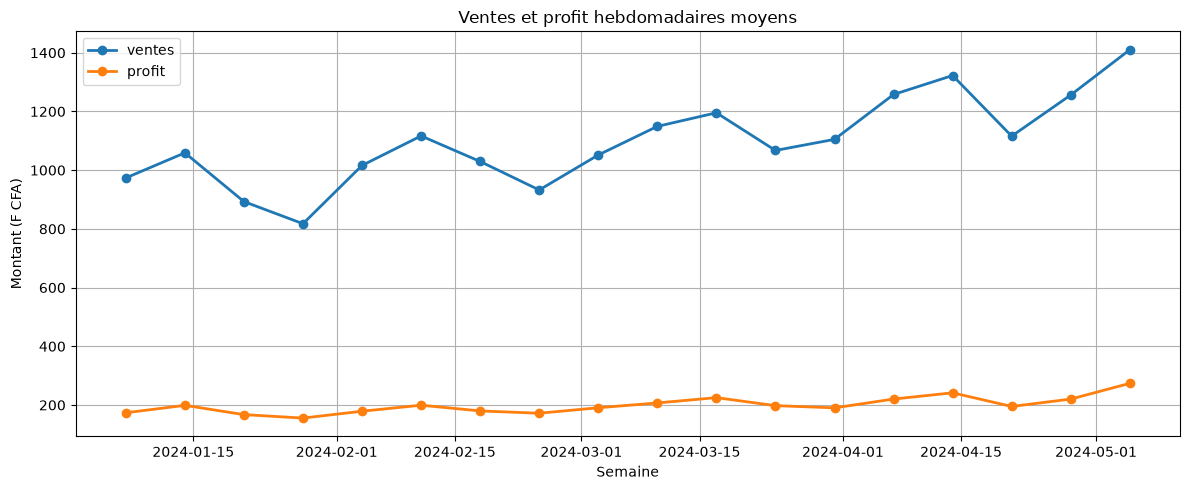

In [3]:
hebdo = ventes.resample('W', on='date')[['ventes', 'profit']].mean().reset_index()

(Chart(hebdo, figsize=(12, 5))
    .line('date', ['ventes', 'profit'])
    .title('Ventes et profit hebdomadaires moyens')
    .labels(xlabel='Semaine', ylabel='Montant (F CFA)')
    .grid()
    .set_legend()
    .tight_layout()
    .show())

## 2. Barres

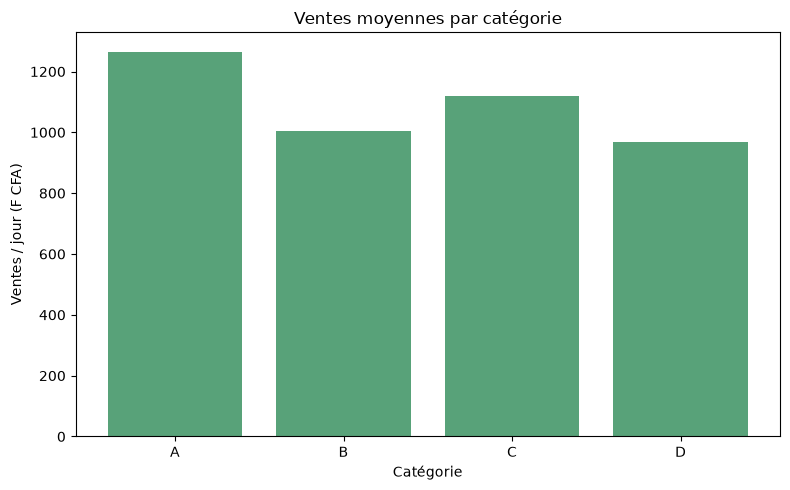

In [4]:
par_categorie = ventes.groupby('categorie', as_index=False)['ventes'].mean()

(Chart(par_categorie, figsize=(8, 5))
    .bar('categorie', 'ventes', color='seagreen')
    .title('Ventes moyennes par catégorie')
    .labels(xlabel='Catégorie', ylabel='Ventes / jour (F CFA)')
    .tight_layout()
    .show())

## 3. Nuage de points

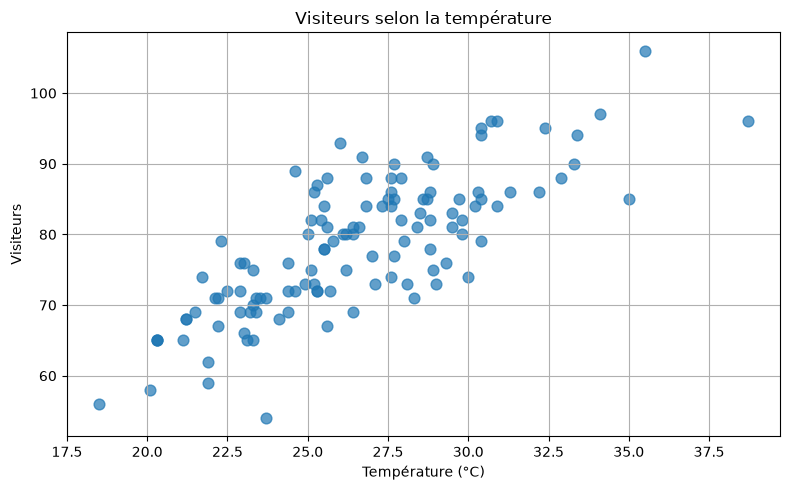

In [5]:
(Chart(ventes, figsize=(8, 5))
    .scatter('temperature', 'visiteurs', size=60)
    .title('Visiteurs selon la température')
    .labels(xlabel='Température (°C)', ylabel='Visiteurs')
    .grid()
    .tight_layout()
    .show())

## 4. Diagramme ombrothermique

Échelle de Gaussen (p = 2T) : un mois est sec quand les précipitations sont inférieures au double de la température.

Analyse des périodes sèches et humides:
Jan: PÉRIODE SÈCHE - Précip: 16.0mm < Seuil: 48.2mm
Fév: PÉRIODE SÈCHE - Précip: 23.9mm < Seuil: 52.2mm
Mar: Période humide - Précip: 86.7mm ≥ Seuil: 53.2mm
Avr: Période humide - Précip: 116.7mm ≥ Seuil: 53.0mm
Mai: Période humide - Précip: 92.9mm ≥ Seuil: 52.2mm
Juin: Période humide - Précip: 147.8mm ≥ Seuil: 50.0mm
Juil: Période humide - Précip: 143.2mm ≥ Seuil: 47.8mm
Août: Période humide - Précip: 215.8mm ≥ Seuil: 47.8mm
Sep: Période humide - Précip: 167.1mm ≥ Seuil: 48.6mm
Oct: Période humide - Précip: 109.4mm ≥ Seuil: 49.6mm
Nov: PÉRIODE SÈCHE - Précip: 30.3mm < Seuil: 49.8mm
Déc: PÉRIODE SÈCHE - Précip: 33.0mm < Seuil: 47.4mm

Résumé: 4 mois secs sur 12 mois


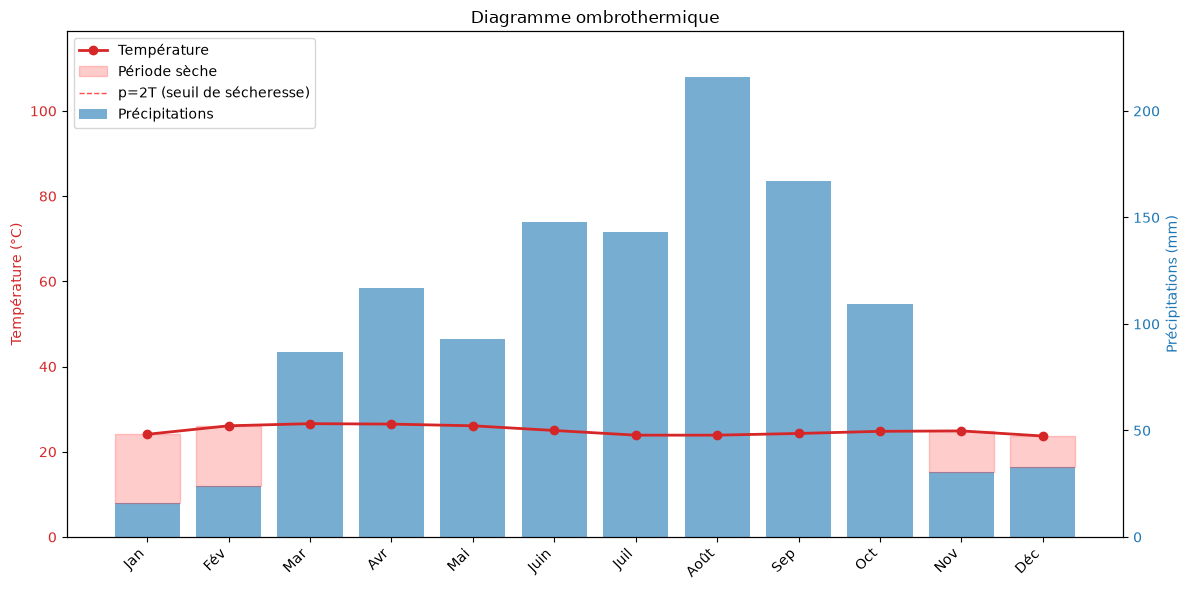

In [6]:
climat = pd.DataFrame({
    'Mois': ['Jan', 'Fév', 'Mar', 'Avr', 'Mai', 'Juin',
             'Juil', 'Août', 'Sep', 'Oct', 'Nov', 'Déc'],
    'Température (°C)': [24.1, 26.1, 26.6, 26.5, 26.1, 25.0,
                         23.9, 23.9, 24.3, 24.8, 24.9, 23.7],
    'Précipitations (mm)': [16, 23.9, 86.7, 116.7, 92.9, 147.8,
                            143.2, 215.8, 167.1, 109.4, 30.3, 33],
})
cols = ('Mois', 'Température (°C)', 'Précipitations (mm)')

(Chart(climat, figsize=(12, 6))
    .ombrothermic(*cols)
    .title('Diagramme ombrothermique')
    .print_ombrothermic_analysis(*cols)
    .tight_layout()
    .show())

## 5. Sciences de la nature

Un essai agronomique fictif : trois variétés de riz, cinq doses d'azote, quatre blocs.

In [7]:
rng = np.random.default_rng(3)
lignes = []
for variete, gain in [('Sahel-108', 0.0), ('IR-841', 0.7), ('Nerica-4', 1.3)]:
    for dose in [0, 30, 60, 90, 120]:
        for bloc in range(1, 5):
            lignes.append({'variete': variete, 'dose': dose, 'bloc': bloc,
                           'rendement': 2.5 + gain + 0.035 * dose - 0.00018 * dose ** 2
                                        + rng.normal(0, 0.3)})
essai = pd.DataFrame(lignes)
essai.head()

,variete,dose,bloc,rendement
0,Sahel-108,0,1,3.112276
1,Sahel-108,0,2,1.733300
2,Sahel-108,0,3,2.625430
3,Sahel-108,0,4,2.329669
4,Sahel-108,30,1,3.252205


### Régression : courbe de réponse à l'azote

Ajustement polynomial, bande de confiance à 95 %, équation et R².

{'coefs': array([-2.07043582e-04,  3.73229013e-02,  3.16931512e+00]), 'r2': np.float64(0.4819982877068384), 'p': None, 'n': 60}


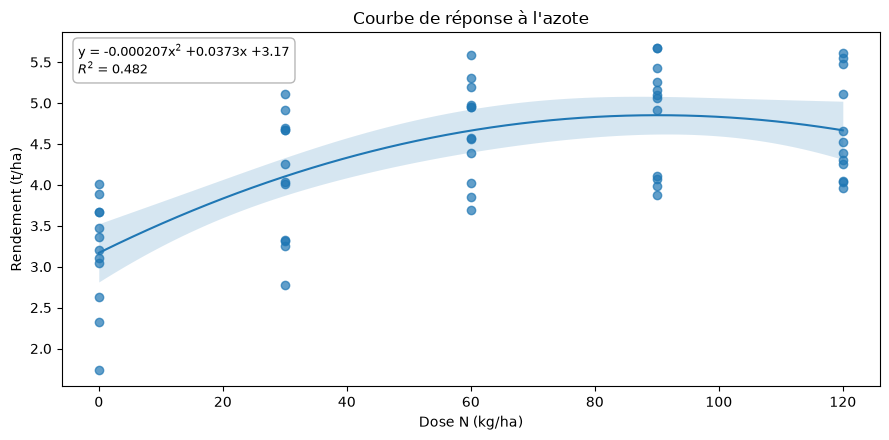

In [8]:
chart = (Chart(essai, figsize=(9, 4.5))
    .regression('dose', 'rendement', order=2)
    .title("Courbe de réponse à l'azote")
    .labels(xlabel='Dose N (kg/ha)', ylabel='Rendement (t/ha)')
    .tight_layout())
print(chart.regression_stats)
chart.show()

### Moyennes ± erreur et lettres de Tukey

Deux barres qui partagent une lettre ne diffèrent pas significativement (Tukey HSD, α = 5 %). Avec `hue`, les variétés sont comparées à l'intérieur de chaque dose.

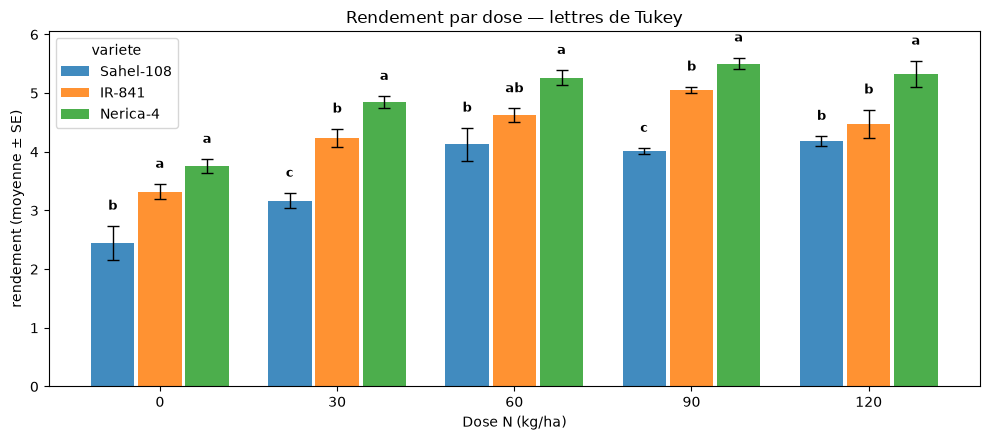

{(0, 'Sahel-108'): 'b',
 (0, 'IR-841'): 'a',
 (0, 'Nerica-4'): 'a',
 (30, 'Sahel-108'): 'c',
 (30, 'IR-841'): 'b',
 (30, 'Nerica-4'): 'a',
 (60, 'Sahel-108'): 'b',
 (60, 'IR-841'): 'ab',
 (60, 'Nerica-4'): 'a',
 (90, 'Sahel-108'): 'c',
 (90, 'IR-841'): 'b',
 (90, 'Nerica-4'): 'a',
 (120, 'Sahel-108'): 'b',
 (120, 'IR-841'): 'b',
 (120, 'Nerica-4'): 'a'}

In [9]:
chart = (Chart(essai, figsize=(10, 4.5))
    .mean_bar('dose', 'rendement', hue='variete', letters=True)
    .title('Rendement par dose — lettres de Tukey')
    .labels(xlabel='Dose N (kg/ha)')
    .tight_layout())
chart.show()
chart.tukey_letters

### Interaction et normalité des résidus

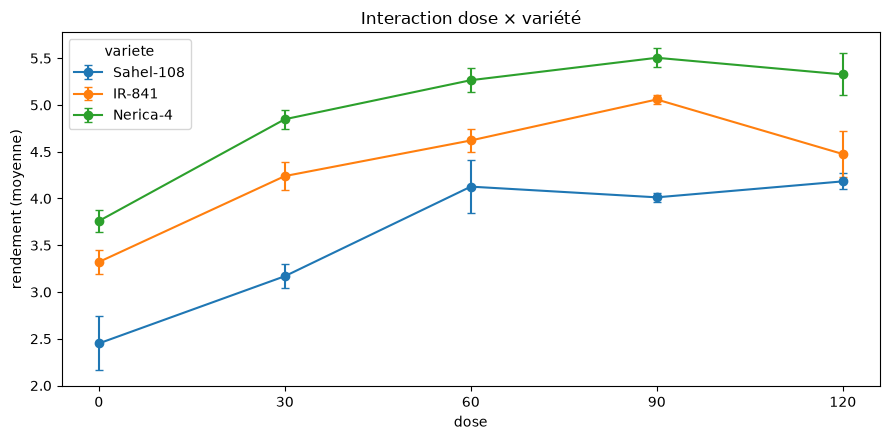

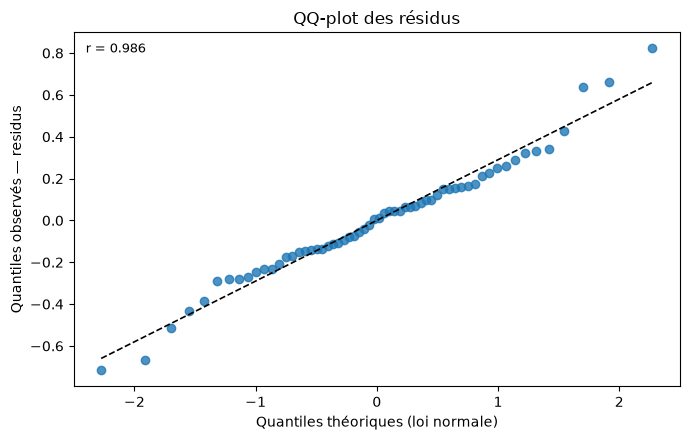

In [10]:
(Chart(essai, figsize=(9, 4.5))
    .interaction('dose', 'variete', 'rendement')
    .title('Interaction dose × variété')
    .tight_layout()
    .show())

essai['residus'] = essai['rendement'] - essai.groupby(['variete', 'dose'])['rendement'].transform('mean')
(Chart(essai, figsize=(7, 4.5))
    .qqplot('residus')
    .title('QQ-plot des résidus')
    .tight_layout()
    .show())

### ACP, dendrogramme et clustermap

Cinq caractères mesurés sur 20 variétés.

Variance expliquée (%) : [69.3 15.7  8.1]


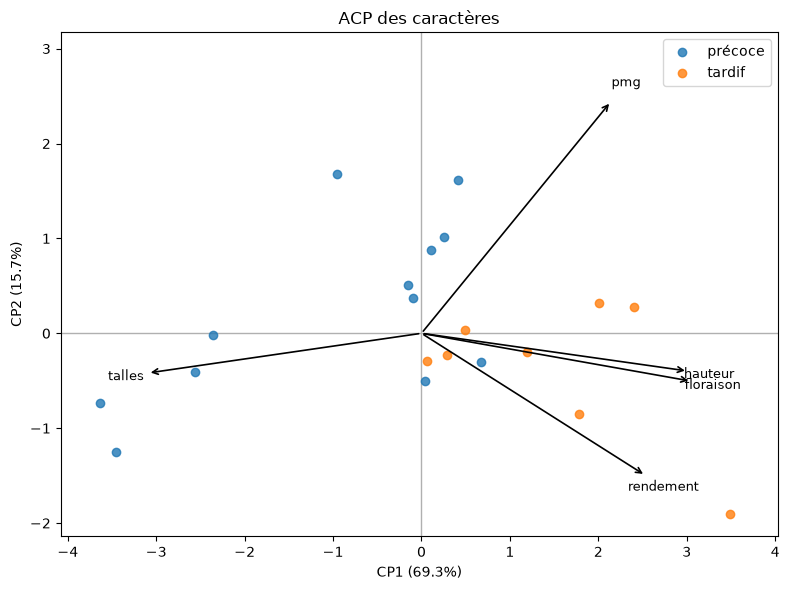

In [11]:
rng = np.random.default_rng(7)
n = 20
precocite = rng.normal(size=n)
caracteres = pd.DataFrame({
    'variete': [f'V{i:02d}' for i in range(n)],
    'cycle': np.where(precocite > 0, 'tardif', 'précoce'),
    'hauteur': 95 + 12 * precocite + rng.normal(0, 5, n),
    'floraison': 85 + 10 * precocite + rng.normal(0, 3, n),
    'talles': 12 - 2 * precocite + rng.normal(0, 1, n),
    'pmg': 25 + rng.normal(0, 2.5, n),
    'rendement': 4.5 + 0.5 * precocite + rng.normal(0, 0.4, n),
})

chart = Chart(caracteres, figsize=(8, 6)).pca_biplot(group='cycle').title('ACP des caractères').tight_layout()
print('Variance expliquée (%) :', (chart.pca['explained_variance_ratio'][:3] * 100).round(1))
chart.show()

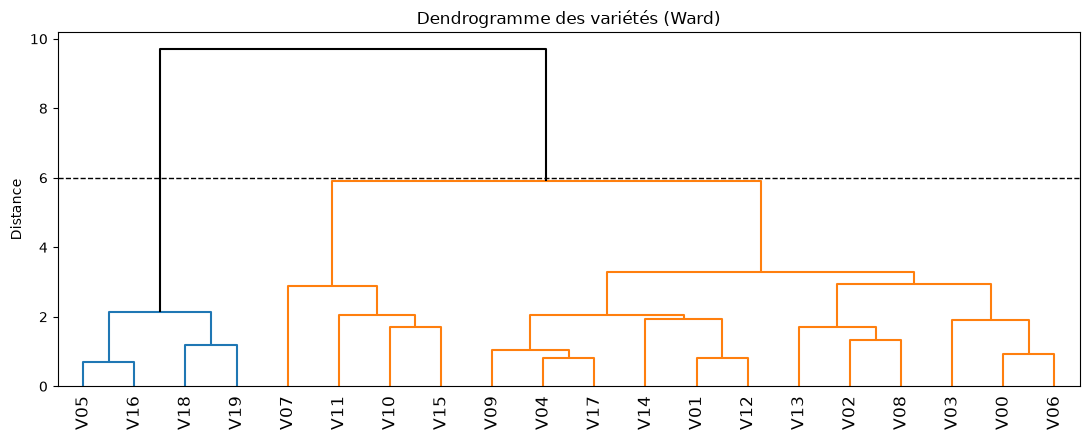

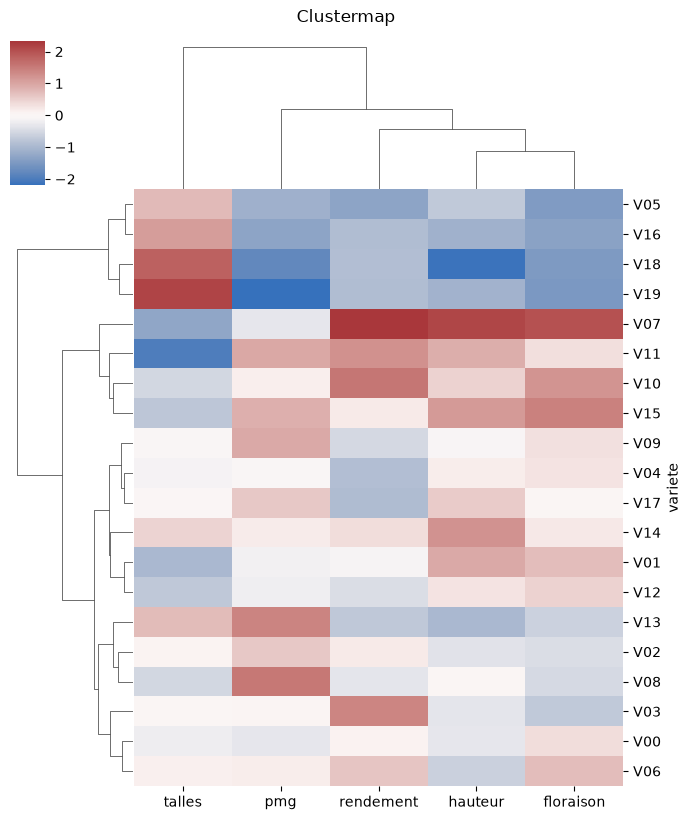

In [12]:
(Chart(caracteres, figsize=(11, 4.5))
    .dendrogram(labels='variete', color_threshold=6)
    .title('Dendrogramme des variétés (Ward)')
    .tight_layout()
    .show())

Chart(caracteres, figsize=(7, 8)).clustermap(labels='variete').title('Clustermap').show()

### Triangle des textures du sol (USDA)

`soil_texture` trace les 12 classes ; `texture_class` classe les échantillons sans tracer.

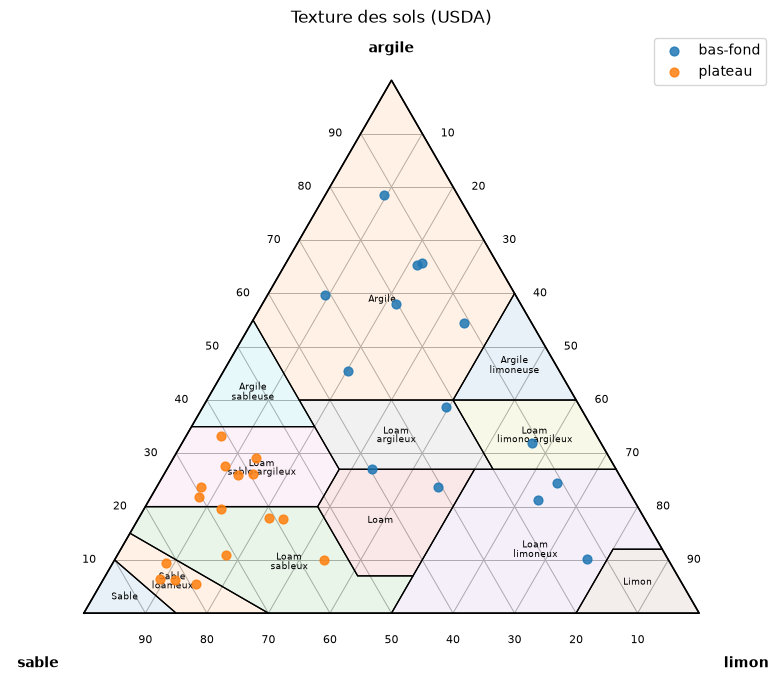

texture
Argile                  7
Loam sablo-argileux     7
Loam sableux            5
Sable loameux           4
Loam limoneux           3
Loam                    2
Loam argileux           1
Loam limono-argileux    1
Name: count, dtype: int64

In [13]:
rng = np.random.default_rng(11)
sols = pd.DataFrame({'zone': rng.choice(['bas-fond', 'plateau'], 30)})
sols['sable'] = np.where(sols['zone'] == 'plateau', rng.uniform(55, 85, 30), rng.uniform(10, 45, 30))
sols['argile'] = rng.uniform(5, 100 - sols['sable'] - 5)
sols['limon'] = 100 - sols['sable'] - sols['argile']

chart = (Chart(sols, figsize=(8, 7.5))
    .soil_texture('sable', 'limon', 'argile', group='zone')
    .title('Texture des sols (USDA)')
    .tight_layout())
chart.show()
chart.texture_classes.value_counts()

In [14]:
texture_class(40, 40, 20), texture_class(10, 80, 10), texture_class(20, 20, 60)

('Loam', 'Limon', 'Argile')

## 6. Graphiques seaborn

`chart.seaborn('nom')` donne accès à toutes les fonctions de seaborn ; les plus courantes ont un raccourci (`kde`, `swarm`, `pairplot`, `jointplot`…).

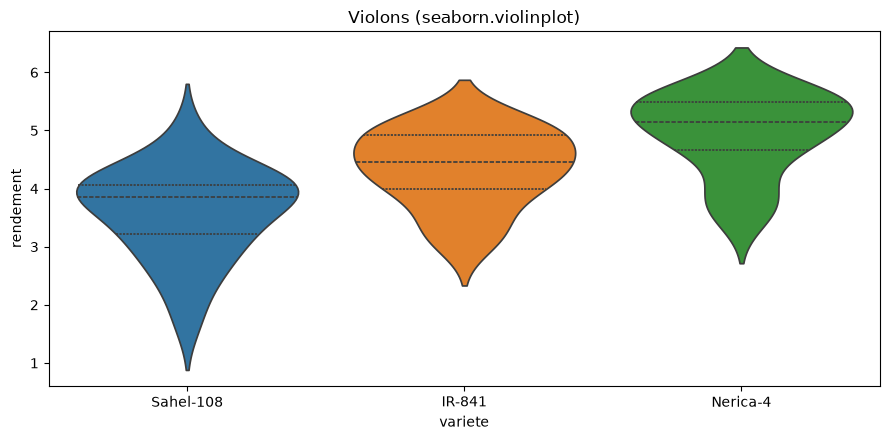

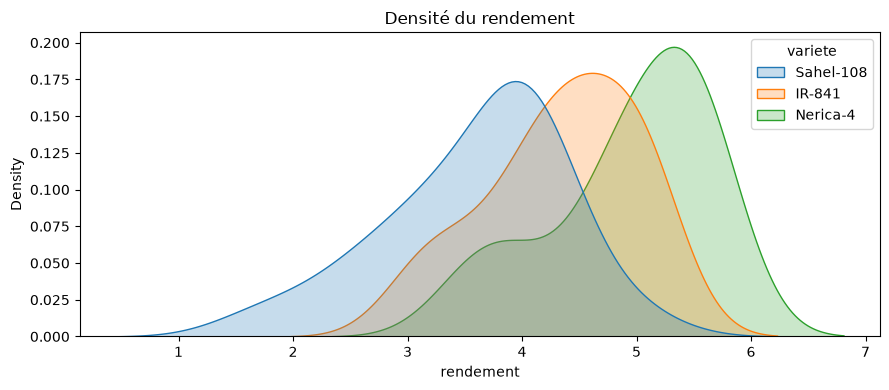

In [15]:
(Chart(essai, figsize=(9, 4.5))
    .seaborn('violinplot', x='variete', y='rendement', hue='variete', inner='quart')
    .title('Violons (seaborn.violinplot)')
    .tight_layout()
    .show())

(Chart(essai, figsize=(9, 4))
    .kde('rendement', hue='variete')
    .title('Densité du rendement')
    .tight_layout()
    .show())

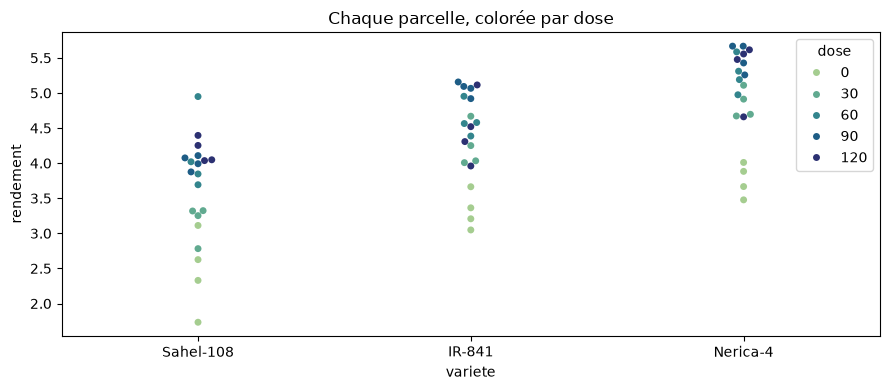

In [16]:
(Chart(essai, figsize=(9, 4))
    .swarm('variete', 'rendement', hue='dose', palette='crest')
    .title('Chaque parcelle, colorée par dose')
    .tight_layout()
    .show())

Les fonctions seaborn à plusieurs panneaux remplacent la figure : `title()` devient le titre général.

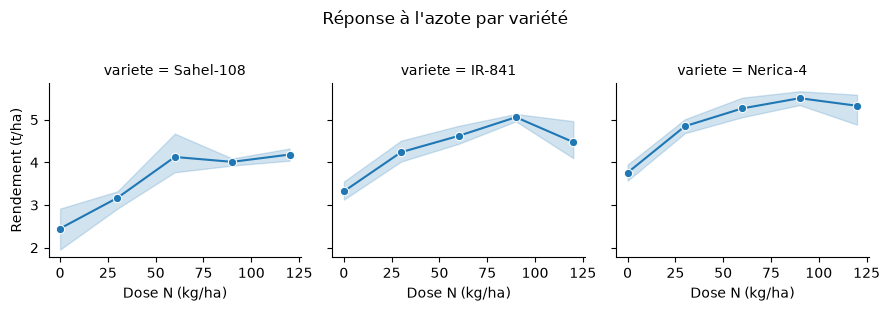

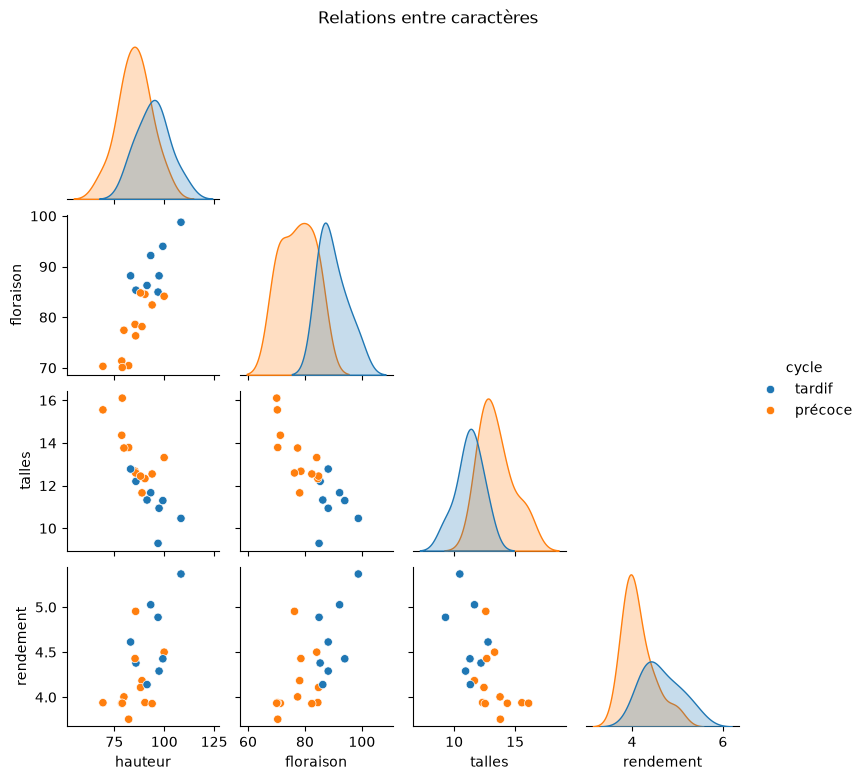

In [17]:
(Chart(essai)
    .seaborn('relplot', x='dose', y='rendement', col='variete', kind='line', marker='o', height=3)
    .title("Réponse à l'azote par variété")
    .labels('Dose N (kg/ha)', 'Rendement (t/ha)')
    .tight_layout()
    .show())

(Chart(caracteres)
    .pairplot(vars=['hauteur', 'floraison', 'talles', 'rendement'], hue='cycle', corner=True, height=1.9)
    .title('Relations entre caractères')
    .show())

## 7. Thèmes

35 thèmes : 14 maison, 5 styles seaborn et 16 morethemes (paquet optionnel). `theme_context` limite un thème à un bloc `with`.

In [18]:
{source: list_themes(source) for source in ['plutovizu', 'seaborn', 'morethemes']}

{'plutovizu': ['accessible',
  'arctic',
  'blueprint',
  'editorial',
  'forest',
  'ink',
  'neon',
  'ocean',
  'paper',
  'pastel',
  'pluto',
  'sahel',
  'sunset',
  'terminal'],
 'seaborn': ['seaborn-dark',
  'seaborn-darkgrid',
  'seaborn-ticks',
  'seaborn-white',
  'seaborn-whitegrid'],
 'morethemes': ['darker',
  'ebonis',
  'economist',
  'ft',
  'greenwave',
  'lighter',
  'lumen',
  'minimal',
  'monoblue',
  'nature',
  'nord',
  'retro',
  'urban',
  'vscode-dark',
  'wsj',
  'yellowish']}

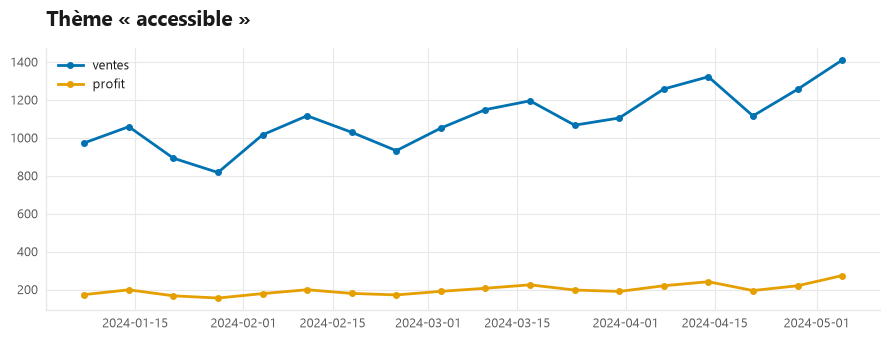

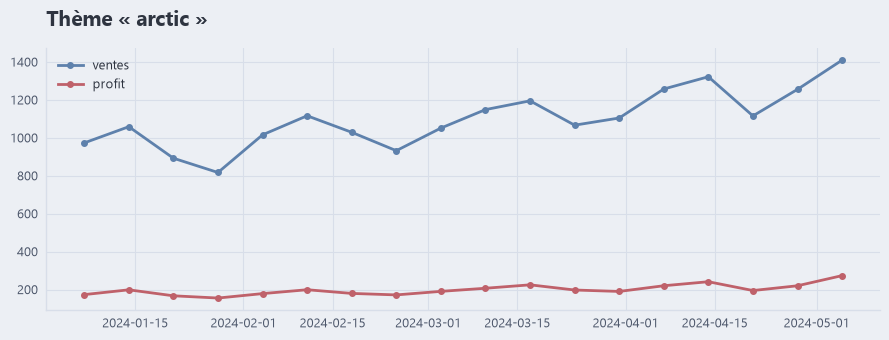

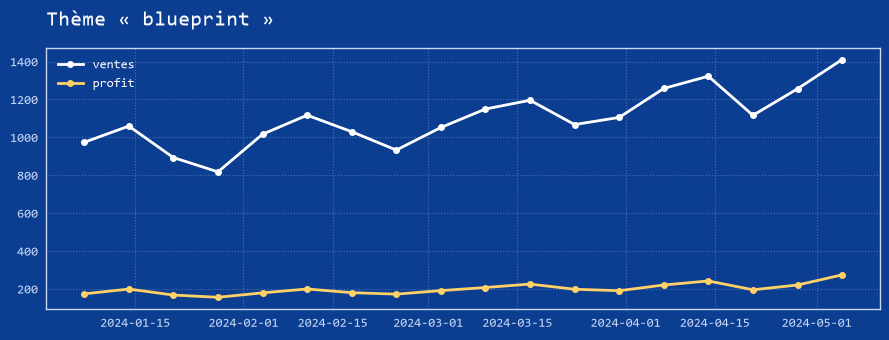

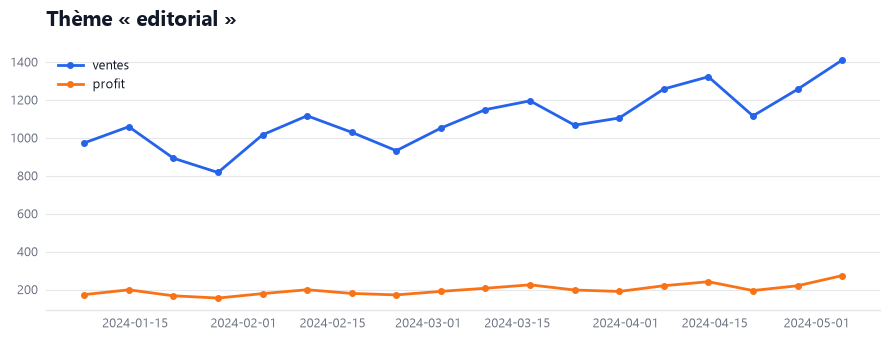

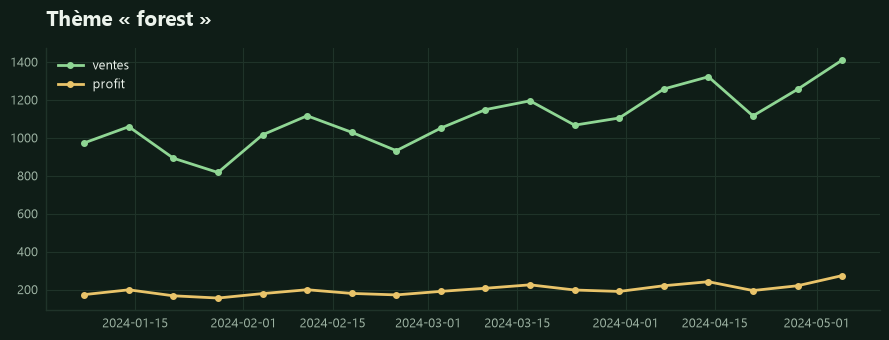

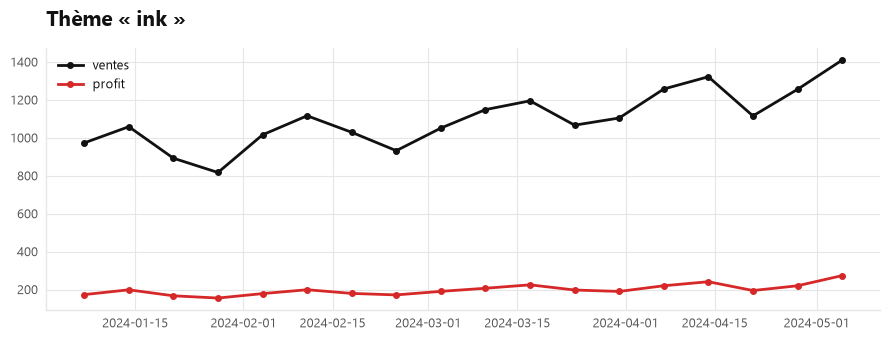

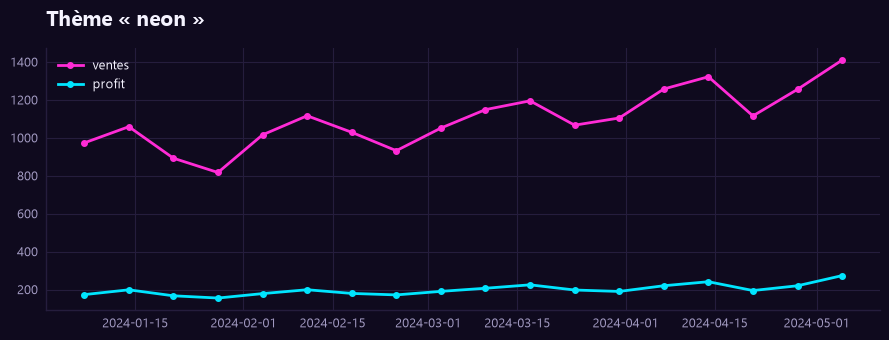

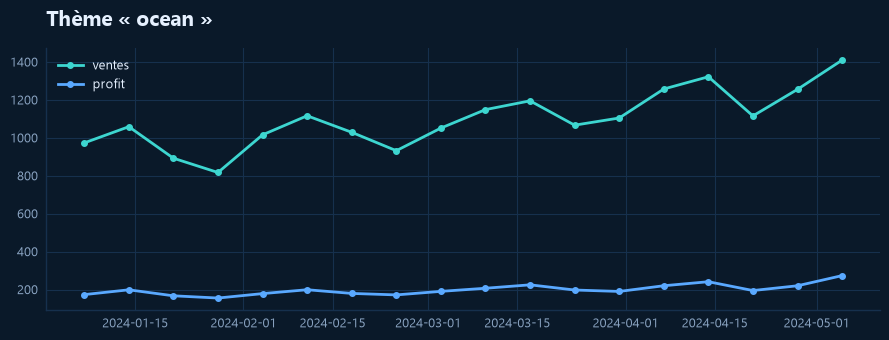

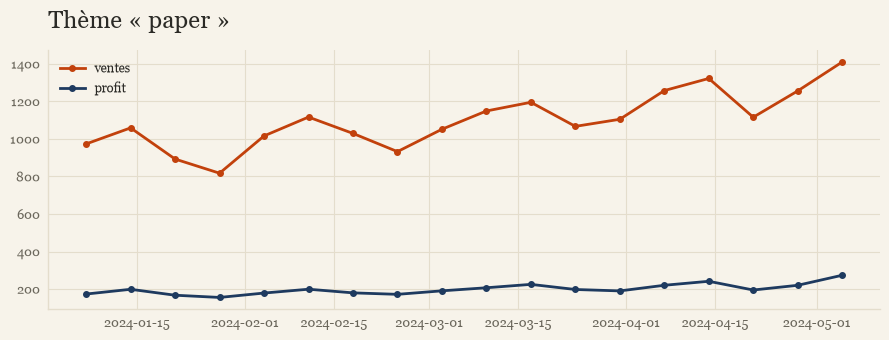

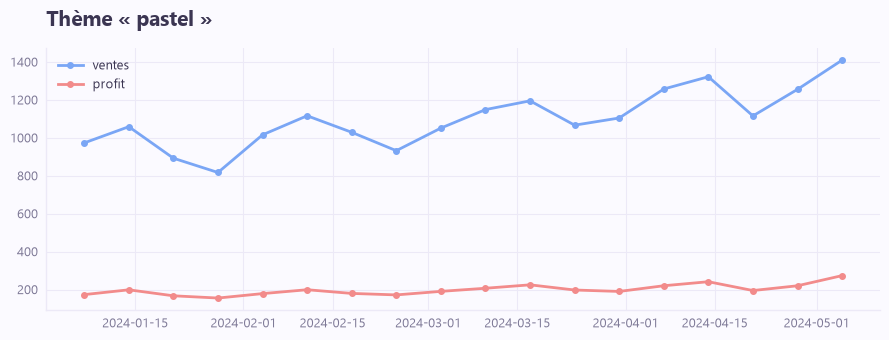

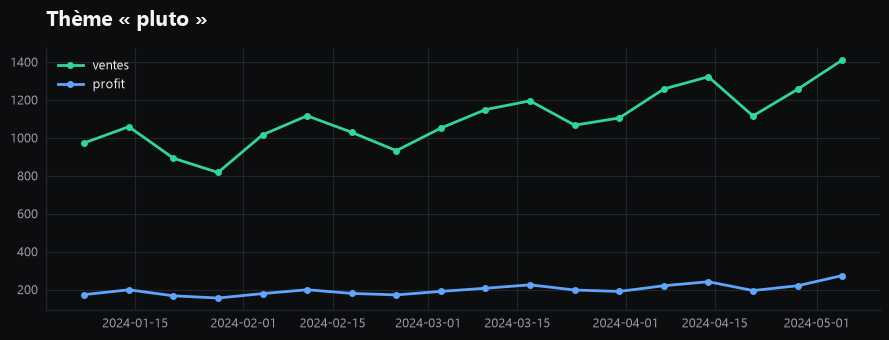

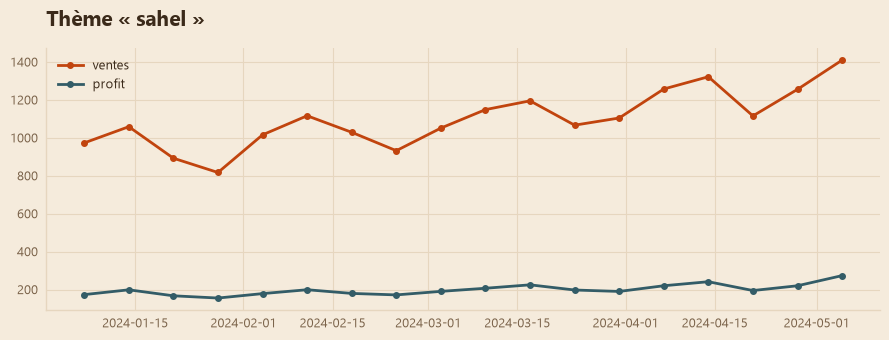

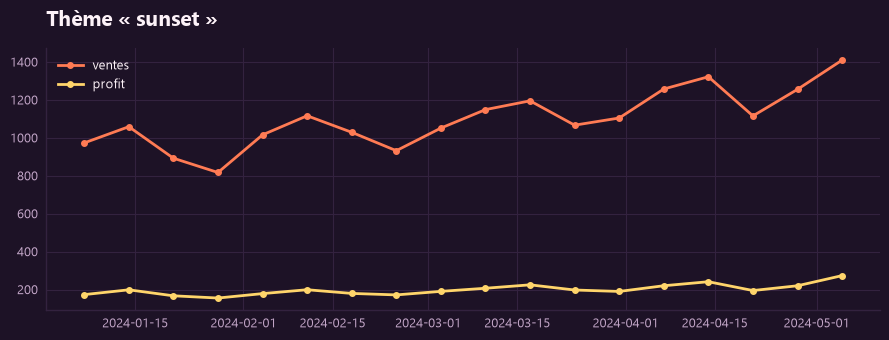

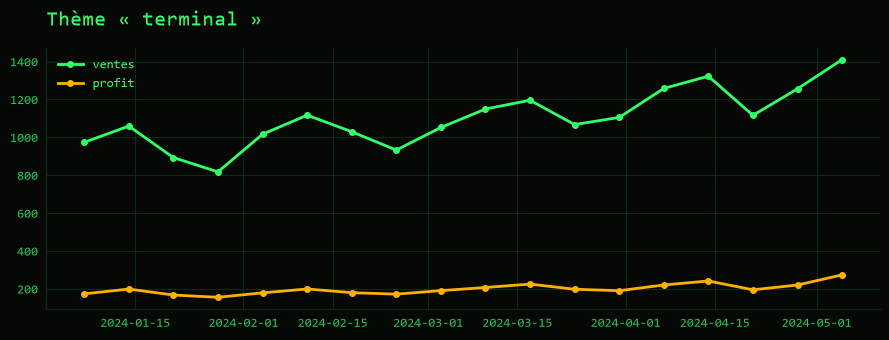

In [19]:
for nom in list_themes('plutovizu'):
    with theme_context(nom):
        (Chart(hebdo, figsize=(9, 3.5))
            .line('date', ['ventes', 'profit'], marker='o', markersize=4)
            .title(f'Thème « {nom} »')
            .set_legend()
            .tight_layout()
            .show())

Quelques styles seaborn et thèmes morethemes (les seconds téléchargent leur police au premier usage) :

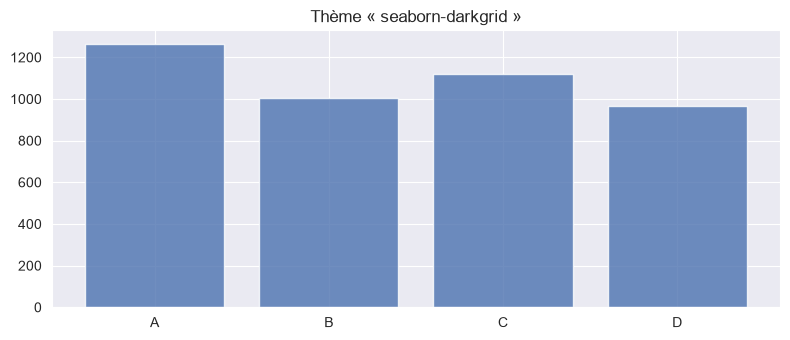

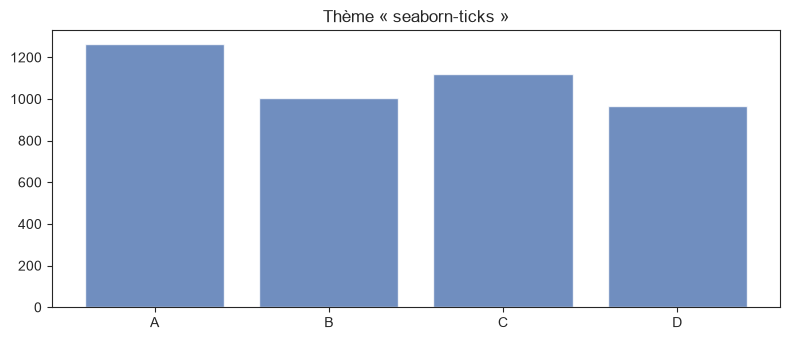

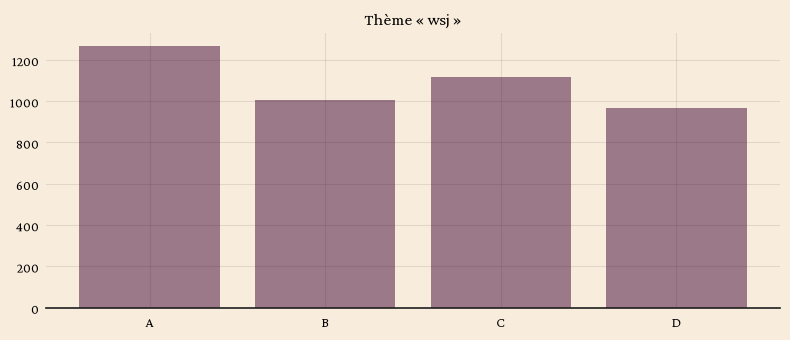

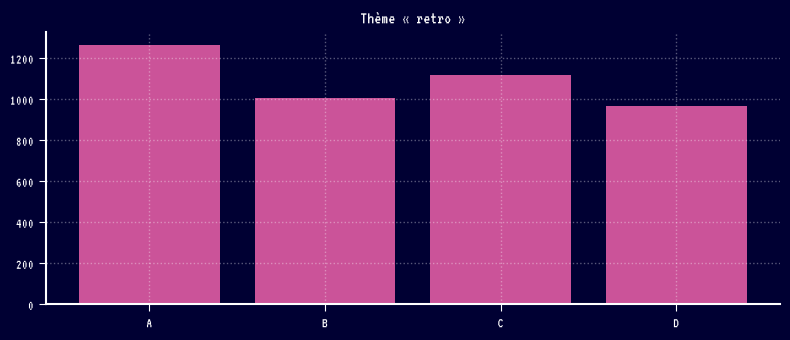

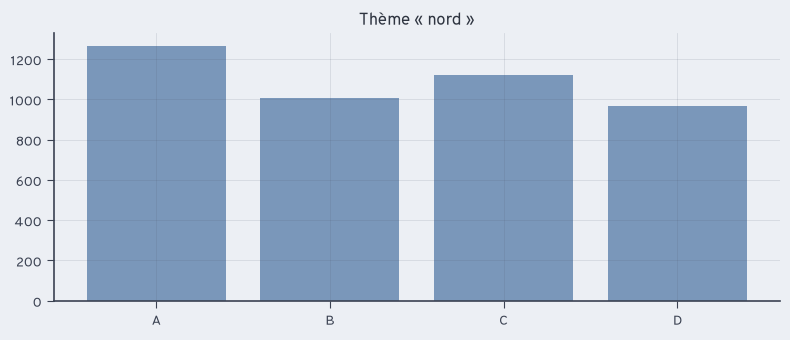

In [20]:
for nom in ['seaborn-darkgrid', 'seaborn-ticks', 'wsj', 'retro', 'nord']:
    with theme_context(nom):
        (Chart(par_categorie, figsize=(8, 3.5))
            .bar('categorie', 'ventes')
            .title(f'Thème « {nom} »')
            .tight_layout()
            .show())

`context` adapte la taille du texte au support (`'paper'`, `'notebook'`, `'talk'`, `'poster'`). `set_theme` applique un thème à toute la session ; `set_theme(None)` revient au style matplotlib.

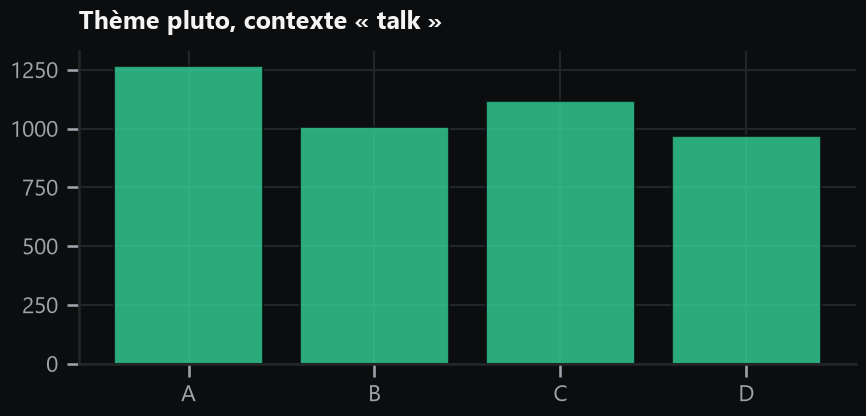

In [21]:
set_theme('pluto', context='talk')
(Chart(par_categorie, figsize=(9, 4.5))
    .bar('categorie', 'ventes')
    .title('Thème pluto, contexte « talk »')
    .tight_layout()
    .show())
set_theme(None)

## 8. Palettes de couleurs

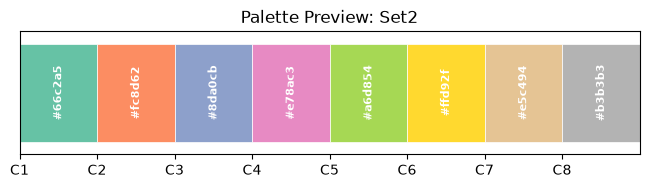

In [22]:
Chart(ventes, figsize=(8, 1.6)).preview_palette('Set2').show()

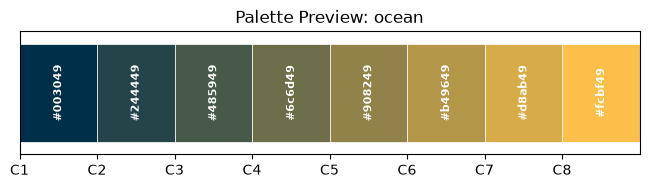

In [23]:
(Chart(ventes, figsize=(8, 1.6))
    .generate_gradient_palette('ocean', '#003049', '#fcbf49', n_colors=8)
    .preview_palette('ocean')
    .show())

## 9. Polices

`font()` modifie la police globale de matplotlib : on l'isole dans `plt.rc_context()` pour ne pas affecter les graphiques suivants.

In [24]:
get_fonts(pattern='Times')

['Times New Roman']

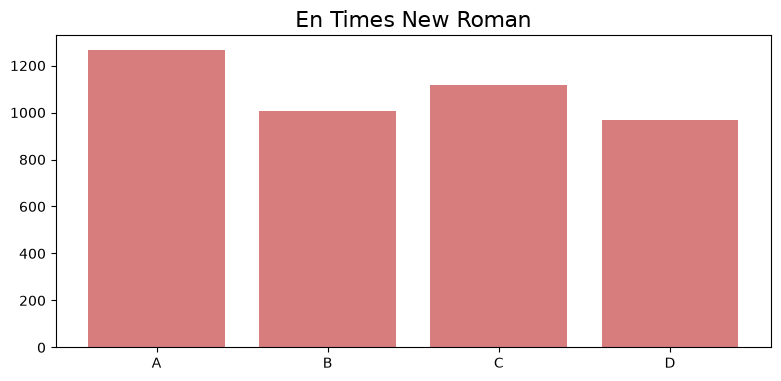

In [25]:
with plt.rc_context():
    (Chart(par_categorie, figsize=(8, 4))
        .font('Times New Roman', size=13)
        .bar('categorie', 'ventes', color='indianred')
        .title('En Times New Roman')
        .tight_layout()
        .show())

## 10. Export

Appeler `save()` **avant** `show()` : `show()` ferme la figure pour libérer la mémoire.

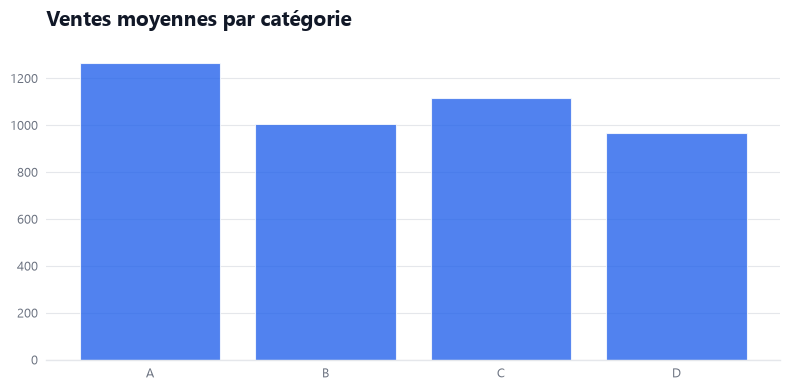

Enregistré : C:\Users\ORDINA~1\AppData\Local\Temp\ventes_par_categorie.png (19 Ko)


In [26]:
fichier = Path(tempfile.gettempdir()) / 'ventes_par_categorie.png'

(Chart(par_categorie, figsize=(8, 4), theme='editorial')
    .bar('categorie', 'ventes')
    .title('Ventes moyennes par catégorie')
    .tight_layout()
    .save(fichier, dpi=150)
    .show())
set_theme(None)
print(f'Enregistré : {fichier} ({fichier.stat().st_size // 1024} Ko)')